# EuroSAT Image Classification with ResNet18

## Objective
Adapt a pretrained ResNet18 model to classify EuroSAT satellite-image patches into 10 land-cover classes.

This notebook demonstrates **transfer learning**: reusing features learned by a pretrained model to train a new classification layer (Fully Connected Layer).

**Workflow:** load data → split data → prepare batches → adapt ResNet18 → train and select a model using validation performance → evaluate on the held-out test set.

## 1. Load the EuroSAT dataset
Using the EuroSAT dataset provided by `torchvision`.

In [ ]:
from torchvision.datasets import EuroSAT

dataset = EuroSAT(
    root="./EuroSAT",
    download=True,
    )
print(dataset)

Dataset EuroSAT
    Number of datapoints: 27000
    Root location: ./EuroSAT


## 2. Create train, validation, and test splits

split images within each class so all splits contain examples from each class.

```text
Dataset/
├── train/<class>/
├── val/<class>/
└── test/<class>/
```



In [ ]:
import os
import random
import shutil

base_path = "Dataset"
train_split = 0.75
test_split = 0.15
seed = 69
random.seed(seed)

# Recreate the generated split directory so old files cannot contaminate this run.
if os.path.exists(base_path):
    shutil.rmtree(base_path)

label_imgs_path = {}
for path, label_idx in dataset.imgs:
    label_imgs_path.setdefault(label_idx, []).append(path)

for label_idx, paths in label_imgs_path.items():
    paths = paths.copy()
    random.shuffle(paths)
    label = dataset.classes[label_idx]

    train_end = int(len(paths) * train_split)
    test_end = train_end + int(len(paths) * test_split)
    splits = {
        "train": paths[:train_end],
        "test": paths[train_end:test_end],
        "val": paths[test_end:],
    }

    for split, image_paths in splits.items():
        label_path = os.path.join(base_path, split, label)
        os.makedirs(label_path, exist_ok=True)
        for image_path in image_paths:
            shutil.copy2(image_path, label_path)

print("Dataset split created.")

Dataset split created.


## 3. Load the splits and transform images

ResNet18 expects three-channel RGB images with dimensions of `3 × 224 × 224` (channels × height × width). Each image is resized to `224 × 224` pixels, converted to a tensor, and normalized using the ImageNet statistics associated with the pretrained weights.

In [ ]:
from torchvision.datasets import ImageFolder
from torchvision import transforms

base_path = "Dataset"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = ImageFolder(f"{base_path}/train", transform=transform)
test_dataset = ImageFolder(f"{base_path}/test", transform=transform)
val_dataset = ImageFolder(f"{base_path}/val", transform=transform)

# Verifying consistent class mappings across all splits
assert train_dataset.class_to_idx == val_dataset.class_to_idx == test_dataset.class_to_idx

print("Datasets loaded successfully.")
print(f"Training images:   {len(train_dataset)}")
print(f"Validation images: {len(val_dataset)}")
print(f"Testing images:    {len(test_dataset)}")
print(f"Number of classes: {len(train_dataset.classes)}")
print(f"Classes: {train_dataset.classes}")

Datasets loaded successfully.
Training images:   20250
Validation images: 2700
Testing images:    4050
Number of classes: 10
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


## 4. Create data loaders


In [ ]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=128, shuffle= True)
test_loader = DataLoader(test_dataset, batch_size= 128)
val_loader = DataLoader(val_dataset, batch_size=128)

## 5. Load pretrained ResNet18 and replace its fully connected layer



In [ ]:
from torchvision.models import resnet18, ResNet18_Weights
import torch.nn as nn

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Freeze the pretrained feature extractor.
for param in model.parameters():
    param.requires_grad = False

# Replace the final classifier for the EuroSAT classes.
in_features = model.fc.in_features
num_classes = len(train_dataset.classes)
model.fc = nn.Linear(in_features, num_classes)


## 6. Configure training


In [ ]:
import torch.optim as optim
import torch.nn as nn

learning_rate = 0.0001
momentum = 0.9
base_lr = 0.0001
max_lr = 0.001
step_size_up = 5  # Number of training batches to ramp up the learning rate.

optimizer = optim.SGD(
    (p for p in model.parameters() if p.requires_grad),
    lr=learning_rate,
    momentum=momentum,
)

criterion = nn.CrossEntropyLoss()

#Learning Rate Scheduler
scheduler = optim.lr_scheduler.CyclicLR(
    optimizer,
    base_lr=base_lr,
    max_lr=max_lr,
    step_size_up=step_size_up,
    cycle_momentum=False,
)

## 7. Selecting the compute device

GPU when available; otherwise, run on CPU.

In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print("Using device:", device)

Using device: cuda


## 8. Training and selecting the best model


In [ ]:
import copy
import numpy as np

epochs = 10
train_loss_history = []
val_accuracy_history = []
best_val_accuracy = 0.0
best_model_state = copy.deepcopy(model.state_dict())

for epoch in range(epochs):
    model.train()
    batch_losses = []

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    scheduler.step()
    mean_train_loss = float(np.mean(batch_losses))
    train_loss_history.append(mean_train_loss)

    model.eval()
    correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()

    val_accuracy = correct / len(val_dataset)
    val_accuracy_history.append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Train loss: {mean_train_loss:.4f} | "
        f"Validation accuracy: {val_accuracy:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

print(f"Best validation accuracy: {best_val_accuracy:.4f}")

Epoch 1/10 | Train loss: 2.0954 | Validation accuracy: 0.5248 | LR: 0.000280
Epoch 2/10 | Train loss: 1.3212 | Validation accuracy: 0.7693 | LR: 0.000460
Epoch 3/10 | Train loss: 0.8203 | Validation accuracy: 0.8474 | LR: 0.000640
Epoch 4/10 | Train loss: 0.5945 | Validation accuracy: 0.8726 | LR: 0.000820
Epoch 5/10 | Train loss: 0.4828 | Validation accuracy: 0.8859 | LR: 0.001000
Epoch 6/10 | Train loss: 0.4141 | Validation accuracy: 0.8985 | LR: 0.000820
Epoch 7/10 | Train loss: 0.3731 | Validation accuracy: 0.9044 | LR: 0.000640
Epoch 8/10 | Train loss: 0.3499 | Validation accuracy: 0.9067 | LR: 0.000460
Epoch 9/10 | Train loss: 0.3356 | Validation accuracy: 0.9085 | LR: 0.000280
Epoch 10/10 | Train loss: 0.3282 | Validation accuracy: 0.9111 | LR: 0.000100
Best validation accuracy: 0.9111


## Restore and load the best model

In [ ]:

model.load_state_dict(best_model_state)


<All keys matched successfully>

## Visualising loss and validation accuracy

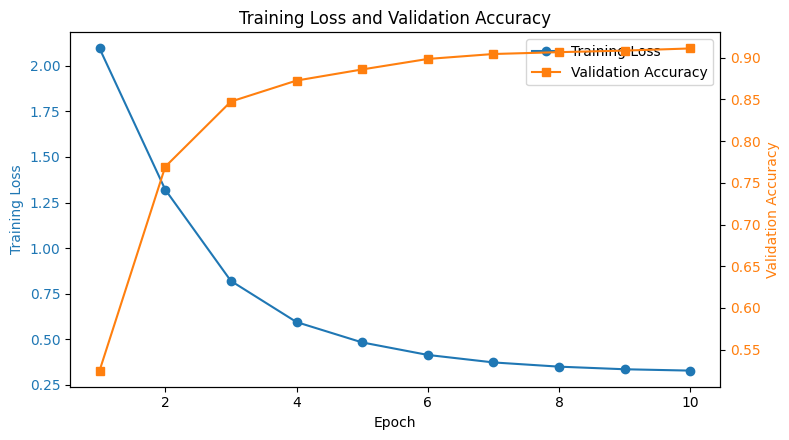

In [ ]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(train_loss_history) + 1)
fig, ax1 = plt.subplots(figsize=(8, 4.5))

line1 = ax1.plot(
    epochs_range, train_loss_history,
    color="tab:blue", marker="o", label="Training Loss"
)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Training Loss", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
line2 = ax2.plot(
    epochs_range, val_accuracy_history,
    color="tab:orange", marker="s", label="Validation Accuracy"
)
ax2.set_ylabel("Validation Accuracy", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

lines = line1 + line2
ax1.legend(lines, [line.get_label() for line in lines])

ax1.set_title("Training Loss and Validation Accuracy")
fig.tight_layout()
plt.show()



Training loss decreased consistently over the 10 epochs, while validation accuracy improved rapidly during the initial epochs before plateauing at approximately 91%. This indicates that the model learned useful features early in training, with diminishing improvements in later epochs.

## 10. Final evaluation on the test set

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

model.eval()
pred_labels = []
actual_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        predictions = model(images).argmax(dim=1)
        pred_labels.extend(predictions.cpu().numpy())
        actual_labels.extend(labels.numpy())

test_accuracy = accuracy_score(actual_labels, pred_labels)
print(f"Test accuracy: {test_accuracy:.4f}")
print(classification_report(
    actual_labels,
    pred_labels,
    target_names=test_dataset.classes,
    zero_division=0,
))



Test accuracy: 0.9067
                      precision    recall  f1-score   support

          AnnualCrop       0.91      0.93      0.92       450
              Forest       0.93      0.95      0.94       450
HerbaceousVegetation       0.90      0.92      0.91       450
             Highway       0.86      0.81      0.83       375
          Industrial       0.92      0.95      0.93       375
             Pasture       0.89      0.89      0.89       300
       PermanentCrop       0.89      0.87      0.88       375
         Residential       0.96      0.96      0.96       450
               River       0.84      0.80      0.82       375
             SeaLake       0.94      0.95      0.95       450

            accuracy                           0.91      4050
           macro avg       0.90      0.90      0.90      4050
        weighted avg       0.91      0.91      0.91      4050



The model achieved an overall test accuracy of 90.67% across 4,050 images from 10 land-cover classes. Residential areas and SeaLake achieved the highest F1-scores (0.96 and 0.95, respectively), while River had the lowest (0.82), followed by Highway (0.83). These differences suggest that the model distinguishes some land-cover classes more reliably than others.

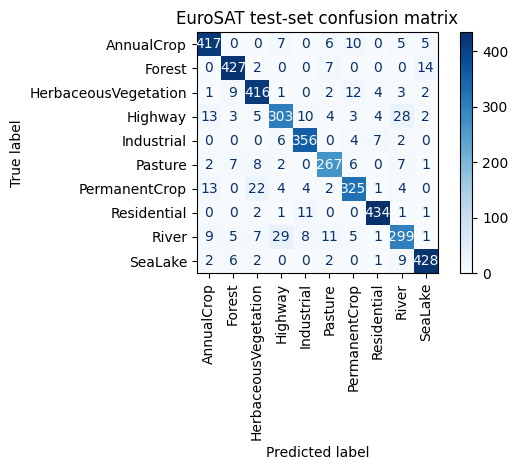

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


cm = confusion_matrix(actual_labels, pred_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes,
)
disp.plot(xticks_rotation=90, cmap="Blues", values_format="d")
plt.title("EuroSAT test-set confusion matrix")
plt.tight_layout()
plt.show()

The confusion matrix shows that most images were correctly classified, with strong diagonal values across the 10 land-cover classes. Misclassifications were more frequent between HerbaceousVegetation and PermanentCrop, and between Highway and River. These errors suggest that some classes have similar visual or spectral characteristics, making them harder for the model to distinguish.